# Notebook 4 of 4: Fine-tuning pretrained African-language models
### Swahili Tweet Sentiment Classification (AfriSenti)

Two pretrained models that saw Swahili in pretraining are fine-tuned on the training tweets, each with a new 3-way classification layer, the same settings and a few random seeds (`SEEDS` in Step 3):

| Model | Hugging Face id | Notes |
|---|---|---|
| AfriBERTa-base | `castorini/afriberta_base` | Small multilingual model (Ogueji et al., 2021) pretrained on 11 African languages |
| AfroXLMR-base | `Davlan/afro-xlmr-base` | XLM-R base adapted to African languages (Alabi et al., 2022); larger |

Each run stops early on **validation macro-F1** and is scored on the test set once. The notebook reports the mean and spread, saves the best-validation model for the web app, optionally uploads it to Hugging Face, and compares all models with bootstrap confidence intervals.

The device is a CUDA GPU if there is one, then the Apple GPU (MPS), then the CPU (much slower). Run time on an 8 GB M2 Mac depends heavily on free memory. The reported setup (2 seeds, 4 epochs, 4 runs) took about an hour; Step 3 is currently set to a quick mode (1 seed, 2 epochs) that should take roughly 10 minutes on an idle Mac, but a test run was stopped after 26 minutes when memory was short. The full plan (10 runs) takes about 20 to 30 minutes on a T4 GPU.

## Step 0 - Set up the project folder

Pick the `.venv` kernel. The next cell moves to the project root and creates the output folders.

In [6]:
from getpass import getpass
from pathlib import Path
import os

# VS Code starts a notebook inside its own folder (notebooks/). Move to the project root so the
# relative paths used below (data/, figures/, results/ ...) resolve from there.
ROOT = Path.cwd().resolve()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "notebooks").is_dir(), "Open the project folder in VS Code and run this notebook from inside it."
os.chdir(ROOT)
print("Project folder:", ROOT)

for folder in ["results/confusion_matrices", "results/metrics", "results/errors", "results/predictions", "figures/finetune", "models"]:
    os.makedirs(folder, exist_ok=True)

Project folder: /Users/manziivan453icloud.com/Downloads/Projects/Ivan /Summative_Technique_I


## Step 1 - GPU check and load the fixed split

In [7]:
import torch, random, time, os, gc, numpy as np, pandas as pd

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")  # Apple GPU (M-series Macs)
else:
    device = torch.device("cpu")
print("Device:", device)
if device.type == "cpu":
    print("WARNING: no GPU found, so training runs on the CPU and will be much slower. Reduce SEEDS and EPOCHS in Step 3 to shorten it.")

LABELS = ["negative", "neutral", "positive"]
N_CLASSES = 3
train = pd.read_csv("data/processed/train.csv")
val = pd.read_csv("data/processed/val.csv")
test = pd.read_csv("data/processed/test.csv")
for df in (train, val, test):
    df["text_clean"] = df["text_clean"].fillna("").astype(str)
print("train:", len(train), " val:", len(val), " test:", len(test))

Device: mps
train: 1810  val: 453  test: 748


## Step 2 - Tokenise with each model's tokenizer

A subword tokenizer splits rare words into known pieces instead of `<UNK>`, the main expected advantage over the BiLSTM for Swahili. The cell shows how a tweet is split, the token lengths and the unknown-token share. It stops if a tokenizer is not a *fast* one, because the web app loads the saved fast tokenizer.

In [8]:
from transformers import AutoTokenizer

MODELS = [
    ("AfriBERTa-base", "castorini/afriberta_base"),
    ("AfroXLMR-base", "Davlan/afro-xlmr-base"),
]
MAX_LEN = 128

tokenizers, enc = {}, {}
for key, hf_id in MODELS:
    tok = AutoTokenizer.from_pretrained(hf_id)
    assert tok.is_fast, f"{hf_id}: not a fast tokenizer. Run: pip install sentencepiece protobuf (in the .venv), restart the kernel, rerun."
    tokenizers[key] = tok
    sample = train["text_clean"].iloc[3]
    print(f"== {key}: vocab {tok.vocab_size:,}")
    print("   ", tok.tokenize(sample)[:25])
    full = [len(x) for x in tok(train["text_clean"].tolist())["input_ids"]]
    print(f"    token length: median {int(np.median(full))}, 99th percentile {int(np.percentile(full, 99))}, "
          f"cut off at {MAX_LEN}: {np.mean(np.array(full) > MAX_LEN):.2%}")
    ids = tok(train["text_clean"].tolist(), add_special_tokens=False)["input_ids"]
    unk = sum(t == tok.unk_token_id for x in ids for t in x) / sum(len(x) for x in ids)
    print(f"    unknown-token share in training tweets: {unk:.2%}")
    enc[key] = {s: tok(df["text_clean"].tolist(), truncation=True, max_length=MAX_LEN)["input_ids"]
                for s, df in [("train", train), ("val", val), ("test", test)]}

== AfriBERTa-base: vocab 70,006
    ['▁kuna', '▁video', '▁ina', 'sambaa', '▁mitandaoni', '▁jamaa', '▁ame', 'mfu', 'mani', 'a', '▁mkewe', '▁akiwa', '▁na', '▁jamaa', '▁mwingine', '▁huku', '▁akim', 'lalamikia', '▁jamaa', '▁aki', 'mwambia', '▁kw']
    token length: median 25, 99th percentile 64, cut off at 128: 0.00%
    unknown-token share in training tweets: 0.00%
== AfroXLMR-base: vocab 250,002
    ['▁kuna', '▁video', '▁ina', 'samba', 'a', '▁mitandao', 'ni', '▁ja', 'maa', '▁am', 'em', 'fu', 'mania', '▁m', 'ke', 'we', '▁akiwa', '▁na', '▁ja', 'maa', '▁mwingine', '▁huku', '▁aki', 'mla', 'lami']
    token length: median 28, 99th percentile 66, cut off at 128: 0.00%
    unknown-token share in training tweets: 0.00%


## Step 3 - Fine-tuning function

Same for every model and seed: learning rate 3e-5 (10% warm-up, then linear decay), batch size 16, up to `EPOCHS` epochs, AdamW with weight decay 0.01, class-weighted loss, mixed precision on a CUDA GPU, early stopping after 3 epochs without validation improvement. The best epoch's weights are scored on the test set once. The Hugging Face "newly initialised weights" warning is expected (the classification layer is new).

**Shortened for speed:** the reported results used `SEEDS = [1, 2]` and `EPOCHS = 4` (the original plan was 5 seeds and up to 8 epochs). The cell below is currently set to a quick mode (`SEEDS = [1]`, `EPOCHS = 2`), which overwrites those results when run. With one or two seeds the spread is only a rough guide.

**Frozen word embeddings** (`FREEZE_EMBEDDINGS = True`): the embedding table (49% of AfriBERTa's weights, 69% of AfroXLMR's) keeps its pretrained values, which roughly halves the time per step on an M2 Mac. Set it to `False` to fine-tune everything.

Say in the report which settings you used; they are saved in `results/metrics/finetune_runs.csv` and `results/metrics_summary.csv`.

In [9]:
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

# QUICK MODE: 1 seed, 2 epochs (roughly 10 minutes on an idle 8 GB Mac, but a test run was stopped after 26 minutes when memory was short).
# The results in results/ and in the report were produced with
# SEEDS = [1, 2] and EPOCHS = 4 (about 1 hour on an 8 GB M2 Mac). Running this notebook as it is now OVERWRITES those results with
# weaker ones; set SEEDS = [1, 2] and EPOCHS = 4 below to reproduce the reported numbers. The original plan was 5 seeds and 8 epochs.
SEEDS = [1]
# True keeps the pretrained word-embedding table fixed and trains only the transformer layers and the classifier.
# About 2x faster per step and much less memory (needed on an 8 GB Mac). Set False to fine-tune everything.
FREEZE_EMBEDDINGS = True
BATCH, EPOCHS, LR, PATIENCE = 16, 2, 3e-5, 3  # EPOCHS shortened from 8
id2label = {i: n for i, n in enumerate(LABELS)}
label2id = {n: i for i, n in id2label.items()}

counts = np.bincount(train["label_id"].values, minlength=N_CLASSES)
class_w = torch.tensor(len(train) / (N_CLASSES * counts), dtype=torch.float).to(device)
criterion = torch.nn.CrossEntropyLoss(weight=class_w)
use_amp = device.type == "cuda"

def scores(y_true, pred):
    return {"accuracy": accuracy_score(y_true, pred), "macro_f1": f1_score(y_true, pred, average="macro"),
            "weighted_f1": f1_score(y_true, pred, average="weighted"),
            "precision_macro": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, pred, average="macro", zero_division=0)}

def make_loader(ids, labels, shuffle, batch, pad_id):
    def collate(b):
        L = max(len(x[0]) for x in b)
        x = torch.full((len(b), L), pad_id, dtype=torch.long); m = torch.zeros((len(b), L), dtype=torch.long)
        for i, (seq, _) in enumerate(b):
            x[i, :len(seq)] = torch.tensor(seq); m[i, :len(seq)] = 1
        return x, m, torch.tensor([y for _, y in b])
    return DataLoader(list(zip(ids, labels)), batch_size=batch, shuffle=shuffle, collate_fn=collate)

def predict(model, loader):
    model.eval(); out = []
    with torch.no_grad():
        for x, m, _ in loader:
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out.append(model(input_ids=x.to(device), attention_mask=m.to(device)).logits.argmax(1).cpu())
    return torch.cat(out).numpy()

best_overall = {"val_f1": -1.0}

def finetune(key, hf_id, seed):
    global best_overall
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    tok = tokenizers[key]
    model = AutoModelForSequenceClassification.from_pretrained(hf_id, num_labels=N_CLASSES, id2label=id2label, label2id=label2id).to(device)
    if FREEZE_EMBEDDINGS:
        model.base_model.embeddings.word_embeddings.weight.requires_grad = False
    tl = make_loader(enc[key]["train"], train["label_id"].tolist(), True, BATCH, tok.pad_token_id)
    vl = make_loader(enc[key]["val"], val["label_id"].tolist(), False, 128, tok.pad_token_id)
    el = make_loader(enc[key]["test"], test["label_id"].tolist(), False, 128, tok.pad_token_id)
    no_decay = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for nme, p in model.named_parameters() if p.requires_grad and not any(nd in nme for nd in no_decay)], "weight_decay": 0.01},
              {"params": [p for nme, p in model.named_parameters() if p.requires_grad and any(nd in nme for nd in no_decay)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR)
    total = EPOCHS * len(tl)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist, best_f1, best_ep, wait, best_state = [], -1.0, 0, 0, None
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); run_loss = 0.0
        for x, m, y in tl:
            x, m, y = x.to(device), m.to(device), y.to(device)
            opt.zero_grad()
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=x, attention_mask=m).logits
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(y)
        vf1 = f1_score(val["label_id"].values, predict(model, vl), average="macro")
        hist.append((run_loss / len(train), vf1))
        print(f"    {key} seed {seed} epoch {ep}/{EPOCHS}: train loss {hist[-1][0]:.3f}, val macro-F1 {vf1:.4f} ({time.time() - t0:.0f}s)")
        if vf1 > best_f1:
            best_f1, best_ep, wait = vf1, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    pred = predict(model, el)
    result = {"model": key, "seed": seed, "freeze_embeddings": FREEZE_EMBEDDINGS, "best_val_f1": best_f1, "best_epoch": best_ep, "epochs_run": len(hist),
              "train_time_s": time.time() - t0, "hist": hist, "pred": pred, **scores(test["label_id"].values, pred)}
    if best_f1 > best_overall["val_f1"]:
        best_overall = {"val_f1": best_f1, "model": key, "seed": seed, "hf_id": hf_id}
        os.makedirs("models/best_sentiment", exist_ok=True)
        model.save_pretrained("models/best_sentiment"); tok.save_pretrained("models/best_sentiment")
    del model, opt, best_state; gc.collect()
    if device.type == "cuda": torch.cuda.empty_cache()
    elif device.type == "mps": torch.mps.empty_cache()
    return result

print(f"Ready. {len(MODELS) * len(SEEDS)} runs ({len(MODELS)} models x {len(SEEDS)} seeds), each up to {EPOCHS} epochs. "
      "On an 8 GB M2 Mac one epoch took about 1 to 3 minutes in tests, depending on free memory.")

Ready. 2 runs (2 models x 1 seeds), each up to 2 epochs. On an 8 GB M2 Mac one epoch took about 1 to 3 minutes in tests, depending on free memory.


## Step 4 - Run every model with every seed

The first run of each model downloads it from Hugging Face. Each epoch prints a progress line. Test numbers are printed for the record but never used to choose anything.

In [ ]:
all_runs = []
for key, hf_id in MODELS:
    for s in SEEDS:
        r = finetune(key, hf_id, s)
        all_runs.append(r)
        print(f"{key:15s} seed {s}: best epoch {r['best_epoch']}/{r['epochs_run']}  val macro-F1 {r['best_val_f1']:.4f}  "
              f"test macro-F1 {r['macro_f1']:.4f}  test acc {r['accuracy']:.4f}  ({r['train_time_s']:.0f}s)")
print()
print("Best validation run overall:", {k: v for k, v in best_overall.items()})

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_base
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    AfriBERTa-base seed 1 epoch 1/2: train loss 0.938, val macro-F1 0.5269 (1397s)
    AfriBERTa-base seed 1 epoch 2/2: train loss 0.688, val macro-F1 0.5155 (1500s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

AfriBERTa-base  seed 1: best epoch 1/2  val macro-F1 0.5269  test macro-F1 0.5497  test acc 0.6083  (1509s)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Step 5 - Mean and spread per model

In [ ]:
runs_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("hist", "pred")} for r in all_runs])
runs_df.to_csv("results/metrics/finetune_runs.csv", index=False)
print(runs_df.round(4).to_string(index=False))
print()
agg = runs_df.groupby("model").agg(
    val_f1_mean=("best_val_f1", "mean"), test_macro_f1_mean=("macro_f1", "mean"), test_macro_f1_std=("macro_f1", "std"),
    test_acc_mean=("accuracy", "mean"), test_weighted_f1_mean=("weighted_f1", "mean"), time_mean=("train_time_s", "mean"))
print(agg.round(4))

         model  seed  freeze_embeddings  best_val_f1  best_epoch  epochs_run  train_time_s  accuracy  macro_f1  weighted_f1  precision_macro  recall_macro
AfriBERTa-base     1               True       0.5224           1           4      349.0343    0.6070    0.5517       0.6024           0.5545        0.5509
AfriBERTa-base     2               True       0.5086           3           4      388.8626    0.6096    0.5639       0.6109           0.5581        0.5706
 AfroXLMR-base     1               True       0.5457           4           4     1977.6941    0.5615    0.5488       0.5678           0.5322        0.5930
 AfroXLMR-base     2               True       0.5336           3           4      796.4342    0.5922    0.5746       0.5973           0.5544        0.6134

                val_f1_mean  test_macro_f1_mean  test_macro_f1_std  \
model                                                                
AfriBERTa-base       0.5155              0.5578             0.0087   
AfroXLMR-base 

## Step 6 - Training curves (the best-validation run of each model)

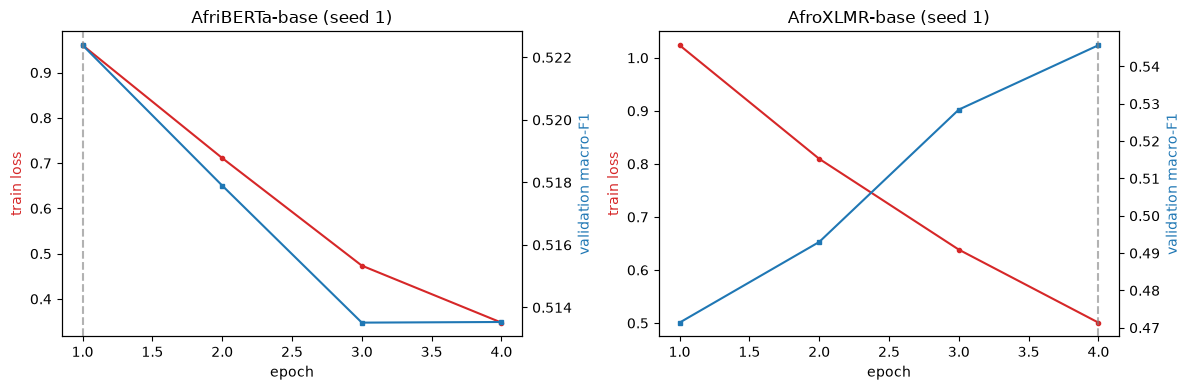

In [ ]:
import matplotlib.pyplot as plt

reps = {}
for key, _ in MODELS:
    rs = [r for r in all_runs if r["model"] == key]
    reps[key] = rs[int(np.argmax([r["best_val_f1"] for r in rs]))]

fig, axes = plt.subplots(1, len(MODELS), figsize=(6 * len(MODELS), 4))
axes = np.atleast_1d(axes)
for ax1, (key, r) in zip(axes, reps.items()):
    ep = range(1, len(r["hist"]) + 1)
    ax1.plot(ep, [h[0] for h in r["hist"]], color="tab:red", marker="o", ms=3)
    ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss", color="tab:red")
    ax2 = ax1.twinx()
    ax2.plot(ep, [h[1] for h in r["hist"]], color="tab:blue", marker="s", ms=3)
    ax2.set_ylabel("validation macro-F1", color="tab:blue")
    ax2.axvline(r["best_epoch"], color="gray", linestyle="--", alpha=0.6)
    ax1.set_title(f"{key} (seed {r['seed']})")
plt.tight_layout()
plt.savefig("figures/finetune/fig_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 7 - Per-class report and confusion matrices

For the best-validation run of each model.

===== AfriBERTa-base (seed 1 )
              precision    recall  f1-score   support

    negative       0.50      0.51      0.51        80
     neutral       0.67      0.72      0.69       444
    positive       0.49      0.42      0.45       224

    accuracy                           0.61       748
   macro avg       0.55      0.55      0.55       748
weighted avg       0.60      0.61      0.60       748



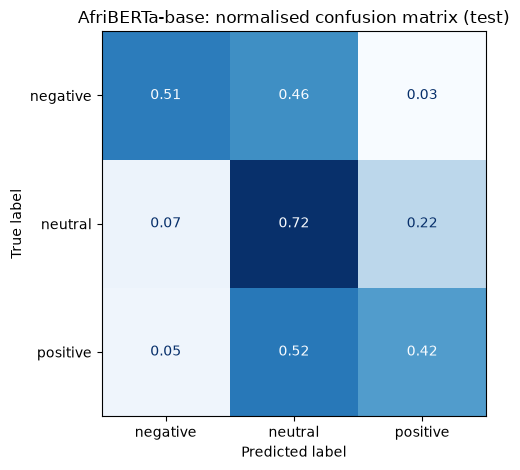

               pred negative  pred neutral  pred positive
true negative             41            37              2
true neutral              29           318             97
true positive             12           117             95

===== AfroXLMR-base (seed 1 )
              precision    recall  f1-score   support

    negative       0.45      0.66      0.54        80
     neutral       0.70      0.53      0.60       444
    positive       0.45      0.58      0.51       224

    accuracy                           0.56       748
   macro avg       0.53      0.59      0.55       748
weighted avg       0.60      0.56      0.57       748



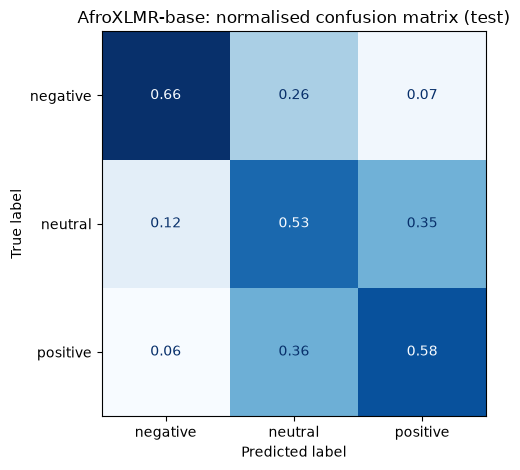

               pred negative  pred neutral  pred positive
true negative             53            21              6
true neutral              52           236            156
true positive             13            80            131



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = test["label_id"].values
for key, r in reps.items():
    print("=====", key, "(seed", r["seed"], ")")
    print(classification_report(y_true, r["pred"], target_names=LABELS, zero_division=0))
    cm = confusion_matrix(y_true, r["pred"], normalize="true")
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{key}: normalised confusion matrix (test)")
    plt.tight_layout()
    fname = key.lower().replace("-", "_")
    plt.savefig(f"results/confusion_matrices/cm_{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(pd.DataFrame(confusion_matrix(y_true, r["pred"]), index=[f"true {l}" for l in LABELS], columns=[f"pred {l}" for l in LABELS]))
    print()

## Step 8 - Save metrics, predictions and errors

In [ ]:
path = "results/metrics_summary.csv"
old = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()
new_rows = []
for key, _ in MODELS:
    sub = runs_df[runs_df["model"] == key]
    new_rows.append({"model_name": f"{key} fine-tuned (mean of seeds)",
        **{k: round(sub[k].mean(), 4) for k in ["accuracy", "macro_f1", "weighted_f1", "precision_macro", "recall_macro"]},
        "macro_f1_std": round(sub["macro_f1"].std(ddof=1), 4), "train_time_s": round(sub["train_time_s"].mean(), 1),
        "notes": f"{len(SEEDS)} seeds; max_len={MAX_LEN}, lr={LR}, batch={BATCH}, epochs<={EPOCHS}, embeddings_frozen={FREEZE_EMBEDDINGS}"})
if len(old):
    old = old[~old["model_name"].isin([r["model_name"] for r in new_rows])]
out = pd.concat([old, pd.DataFrame(new_rows)], ignore_index=True)
out.to_csv(path, index=False)
print(out[["model_name", "accuracy", "macro_f1", "macro_f1_std", "weighted_f1"]].to_string(index=False))

for key, r in reps.items():
    fname = key.lower().replace("-", "_")
    pd.DataFrame({"id": test["id"], "true": y_true, "pred": r["pred"]}).to_csv(f"results/predictions/{fname}_test_preds.csv", index=False)
    errs = test.assign(pred=r["pred"])
    errs = errs[errs["label_id"] != errs["pred"]].copy()
    errs["pred_name"] = errs["pred"].map(lambda i: LABELS[i])
    errs[["id", "text", "label", "pred_name"]].to_csv(f"results/errors/{fname}_errors.csv", index=False)
    print(key, "misclassified:", len(errs), "of", len(test))
    print(errs.groupby(["label", "pred_name"]).size().sort_values(ascending=False).to_string())

                               model_name  accuracy  macro_f1  macro_f1_std  weighted_f1
          Majority class (always neutral)    0.5936    0.2483           NaN       0.4422
                Random by class frequency    0.4358    0.3213           NaN       0.4357
                          TF-IDF + LogReg    0.5802    0.4829           NaN       0.5737
                   BiLSTM (mean of seeds)    0.4749    0.4102        0.0505       0.4888
AfriBERTa-base fine-tuned (mean of seeds)    0.6083    0.5578        0.0087       0.6067
 AfroXLMR-base fine-tuned (mean of seeds)    0.5769    0.5617        0.0182       0.5825
AfriBERTa-base misclassified: 294 of 748
label     pred_name
positive  neutral      117
neutral   positive      97
negative  neutral       37
neutral   negative      29
positive  negative      12
negative  positive       2
AfroXLMR-base misclassified: 328 of 748
label     pred_name
neutral   positive     156
positive  neutral       80
neutral   negative      52
negative  neu

## Step 9 - Is the difference between models bigger than chance?

With 748 test tweets a small gap can be noise. A **bootstrap** resamples the test tweets many times and recomputes macro-F1; the middle 95% is a confidence interval. A **paired** bootstrap uses the same resamples for two models, the fair way to test whether one is really better. It uses the best-validation run of each model and the baseline's predictions.

In [ ]:
import json
from sklearn.metrics import f1_score

pred_files = {
    "TF-IDF + LogReg": "results/predictions/tfidf_test_preds.csv",
    "BiLSTM": "results/predictions/bilstm_test_preds.csv",
}
for key, _ in MODELS:
    pred_files[key] = f"results/predictions/{key.lower().replace('-', '_')}_test_preds.csv"

P = {}
for name, f in pred_files.items():
    if os.path.exists(f):
        d = pd.read_csv(f)
        assert (d["true"].values == y_true).all(), "test order differs"
        P[name] = d["pred"].values
    else:
        print("missing", f)

rng = np.random.default_rng(0)
B = 1000
idx = rng.integers(0, len(y_true), size=(B, len(y_true)))
boot = {name: np.array([f1_score(y_true[i], p[i], average="macro") for i in idx]) for name, p in P.items()}

rows = []
for name, v in boot.items():
    rows.append({"model": name, "macro_f1": round(f1_score(y_true, P[name], average="macro"), 4),
                 "ci_low": round(np.percentile(v, 2.5), 4), "ci_high": round(np.percentile(v, 97.5), 4)})
ci = pd.DataFrame(rows)
print(ci.to_string(index=False))

best_name = ci.sort_values("macro_f1", ascending=False).iloc[0]["model"]
print("\nPaired difference in macro-F1 versus the top model:", best_name)
diffs = []
for name in P:
    if name == best_name:
        continue
    d = boot[best_name] - boot[name]
    lo, hi = np.percentile(d, [2.5, 97.5])
    diffs.append({"versus": name, "mean_diff": round(d.mean(), 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4),
                  "clearly_better": bool(lo > 0)})
dd = pd.DataFrame(diffs)
print(dd.to_string(index=False))
ci.to_csv("results/metrics/bootstrap_ci.csv", index=False)
dd.to_csv("results/metrics/bootstrap_paired_diff.csv", index=False)

          model  macro_f1  ci_low  ci_high
TF-IDF + LogReg    0.4829  0.4393   0.5263
         BiLSTM    0.4664  0.4289   0.5045
 AfriBERTa-base    0.5517  0.5088   0.5889
  AfroXLMR-base    0.5488  0.5085   0.5873

Paired difference in macro-F1 versus the top model: AfriBERTa-base
         versus  mean_diff  ci_low  ci_high  clearly_better
TF-IDF + LogReg     0.0680  0.0139   0.1191            True
         BiLSTM     0.0845  0.0359   0.1345            True
  AfroXLMR-base     0.0025 -0.0432   0.0454           False


**How to read this:** if the interval for a difference includes 0 (`clearly_better` is False), the top model cannot be called better. Say so in the report.

## Step 10 - Upload the best model to Hugging Face (optional)

The web app uses the local `models/best_sentiment` folder, so this is only needed to deploy the app online or share the model (the app then falls back to the repo in `results/metrics/deployed_model.json`).

1. Make a free account at [huggingface.co](https://huggingface.co/join)
2. Create a token with **Write** access at [huggingface.co/settings/tokens](https://huggingface.co/settings/tokens)
3. Run the cell below and type the token into the hidden prompt

In [ ]:
from huggingface_hub import login, HfApi

print("Model to upload:", best_overall)
HF_USERNAME = input("Hugging Face username: ").strip()
HF_REPO = input("Model repo name (for example swahili-sentiment-afrisenti): ").strip()
login(token=getpass("Hugging Face write token (hidden): "))

repo_id = f"{HF_USERNAME}/{HF_REPO}"
api = HfApi()
api.create_repo(repo_id, exist_ok=True)
api.upload_folder(folder_path="models/best_sentiment", repo_id=repo_id)
json.dump({"hf_repo_id": repo_id, **best_overall}, open("results/metrics/deployed_model.json", "w"), indent=2)
print("Uploaded:", f"https://huggingface.co/{repo_id}")
print("Files:", sorted(api.list_repo_files(repo_id)))

NameError: name 'best_overall' is not defined